In [1]:
from mt_rent_statement import *

### Load data

In [2]:
start='2026-06-01'
end='2026-06-30'
dfT=load_tenancies('all_tenancies.xls')
dfAll=load_data(start,end)
dfAll.head(3)

Reading file: C:\Work\Mat\property\data\property\checked\JUN2026_codedAndCategorised.xlsx


C:\Users\mathe\anaconda3\envs\Python36\lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-06-01,60-83-71 00558156,850.00,REVENUE,"Rent for period 29/05/26-28/06/26 Mr Md Lodi, ...",196BKIN,NaN,OurRent,NaN
2026-06-01,60-83-71 00558156,-850.00,REVENUE,Fox & Sons fee,196BKIN,NaN,PropertyExpense,NaN
2026-06-01,20-74-09 40406538,-16.24,Contactless Card Purchase,CO OPERATIVE FOOD ON 30 MAY CLP,NaN,NaN,PersonalExpense,COOP


### Rent Statement

In [3]:
paidinadvancelist = []
inarrearslist = []
dfRs=get_rent_statement(dfAll, dfT, start, end, inarrearslist, paidinadvancelist)
dfRs=dfRs.round(0)
#dfRs.sort_values(by=['Net'], ascending=False).style.apply(custom_style, axis=1)
#dfRs.sort_values(by=['Bills'], ascending=True).style.apply(custom_style, axis=1)
#dfRs.style.apply(custom_style, axis=1)
num_cols = dfRs.select_dtypes(include=["number"]).columns
dfRs.style.format({c: "{:.0f}" for c in num_cols}).apply(custom_style, axis=1)

,Tenant,Agent,Received,Bills,Mortgage,Net,Status
Property,,,,,,,
321 London Rd,,,0,0,0,0,
Flat 1 - 321 London Rd,Ruksana Akter Chowdhury (09/08/2023),0,775,0,-392,383,Paid
Flat 2 - 321 London Rd,Mr Jake Bishop (16/03/2026),0,875,0,-376,499,Paid
Flat 3 - 321 London Rd,Harold Lingard-Kay & Stephen Cressdee (24/04/2026),0,1000,0,-315,685,Paid
Flat 4 - 321 London Rd,Chloe Freshney & Harry Aldingtons (31/01/2023),0,800,-149,-392,259,Paid
169 Fawcett Rd,,,0,0,0,0,
Flat 1 - 169 Fawcett Rd,Miss Letisha Lowe (14/11/2025),0,825,0,-353,472,Paid
Flat 2 - 169 Fawcett Rd,Matthew Granil (31/07/2024),0,775,0,-313,462,Paid
Flat 3 - 169 Fawcett Rd,Mr William Sait (30/06/2025-27/07/2026),0,825,0,-378,447,Paid


Notes:
- More than £4000 was paid this month on 12-14 Alhambra Road elect

Remarks:
- each 0.25% increase in rates causes an increase in costs of £750 - ideally we need rates back at 4.5% to pay £22500 p/m
- find out what happens when a business loans money to another and it is not repaid - ask Chatgpt
- things should improve in March - by then hopefully empties rented, paid in advance start to pay again in March


### Income/Expenditure per Property

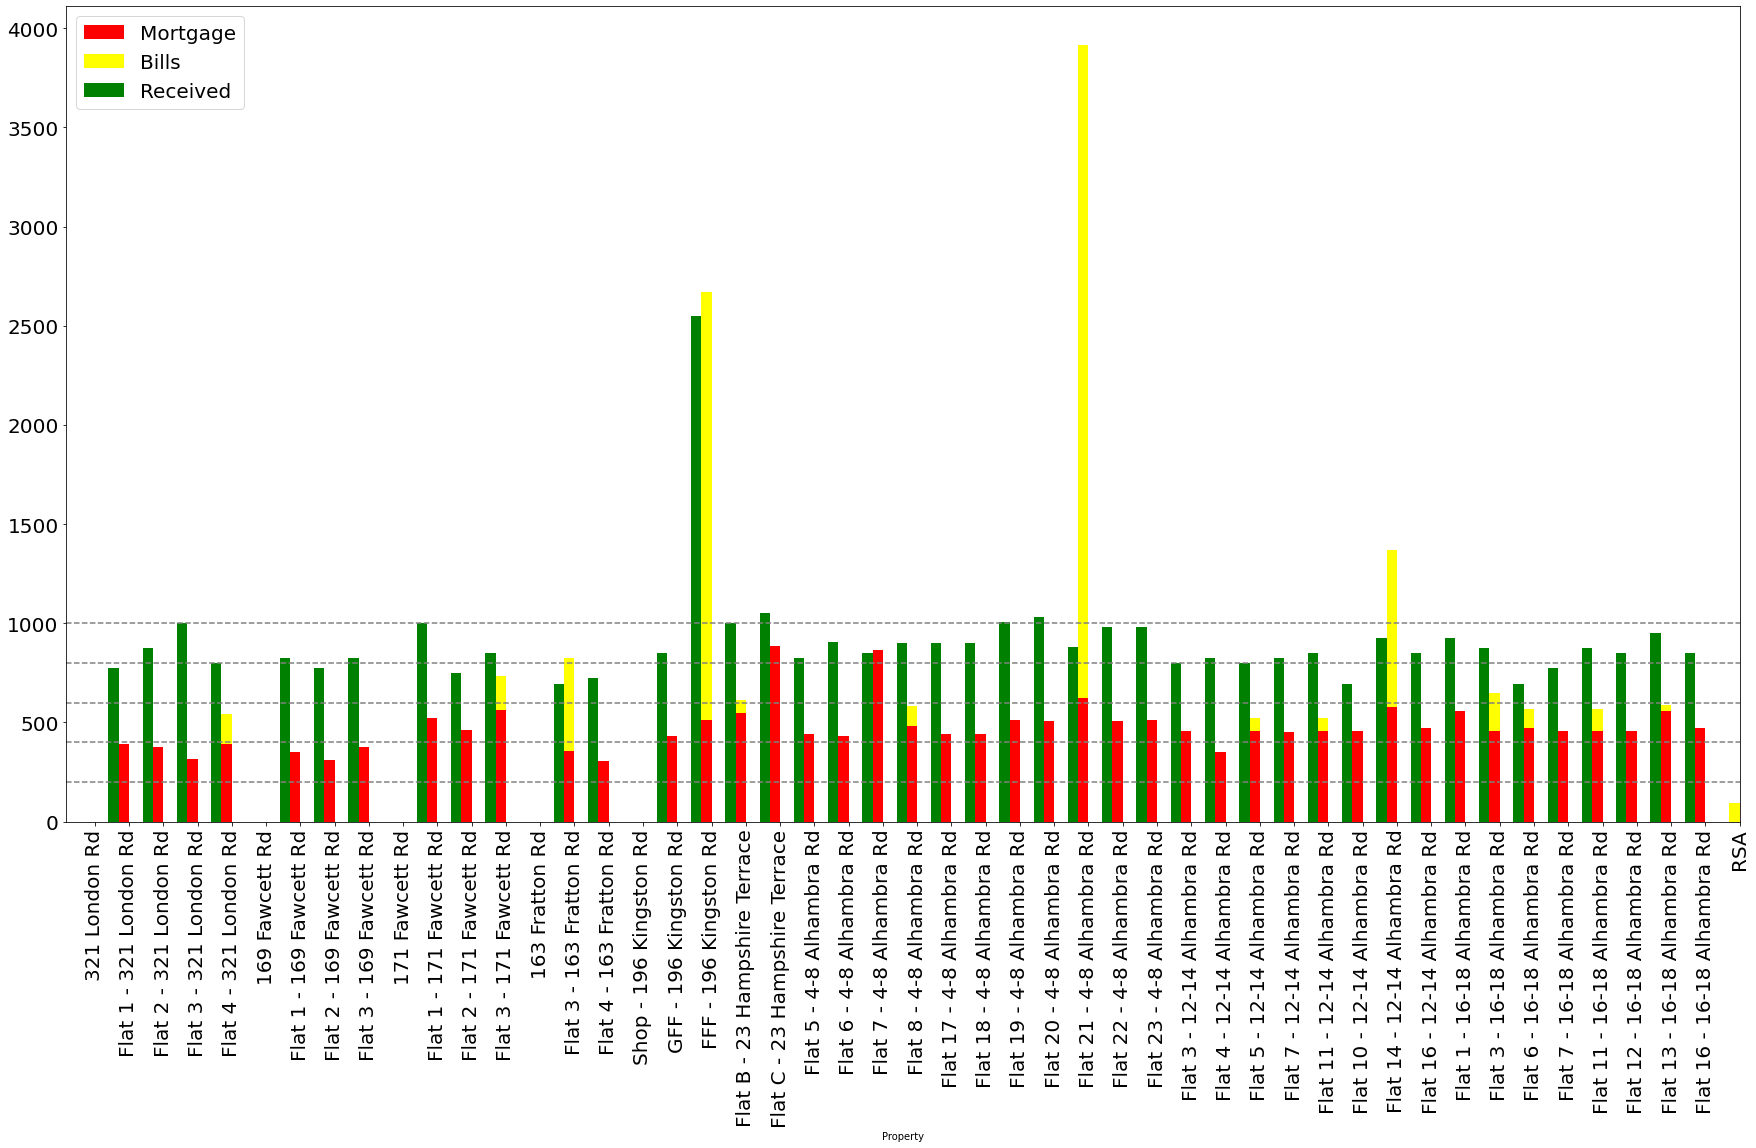

In [4]:
plot_income_expenditure_per_property(dfRs[:-1])

### Net Income Per Property

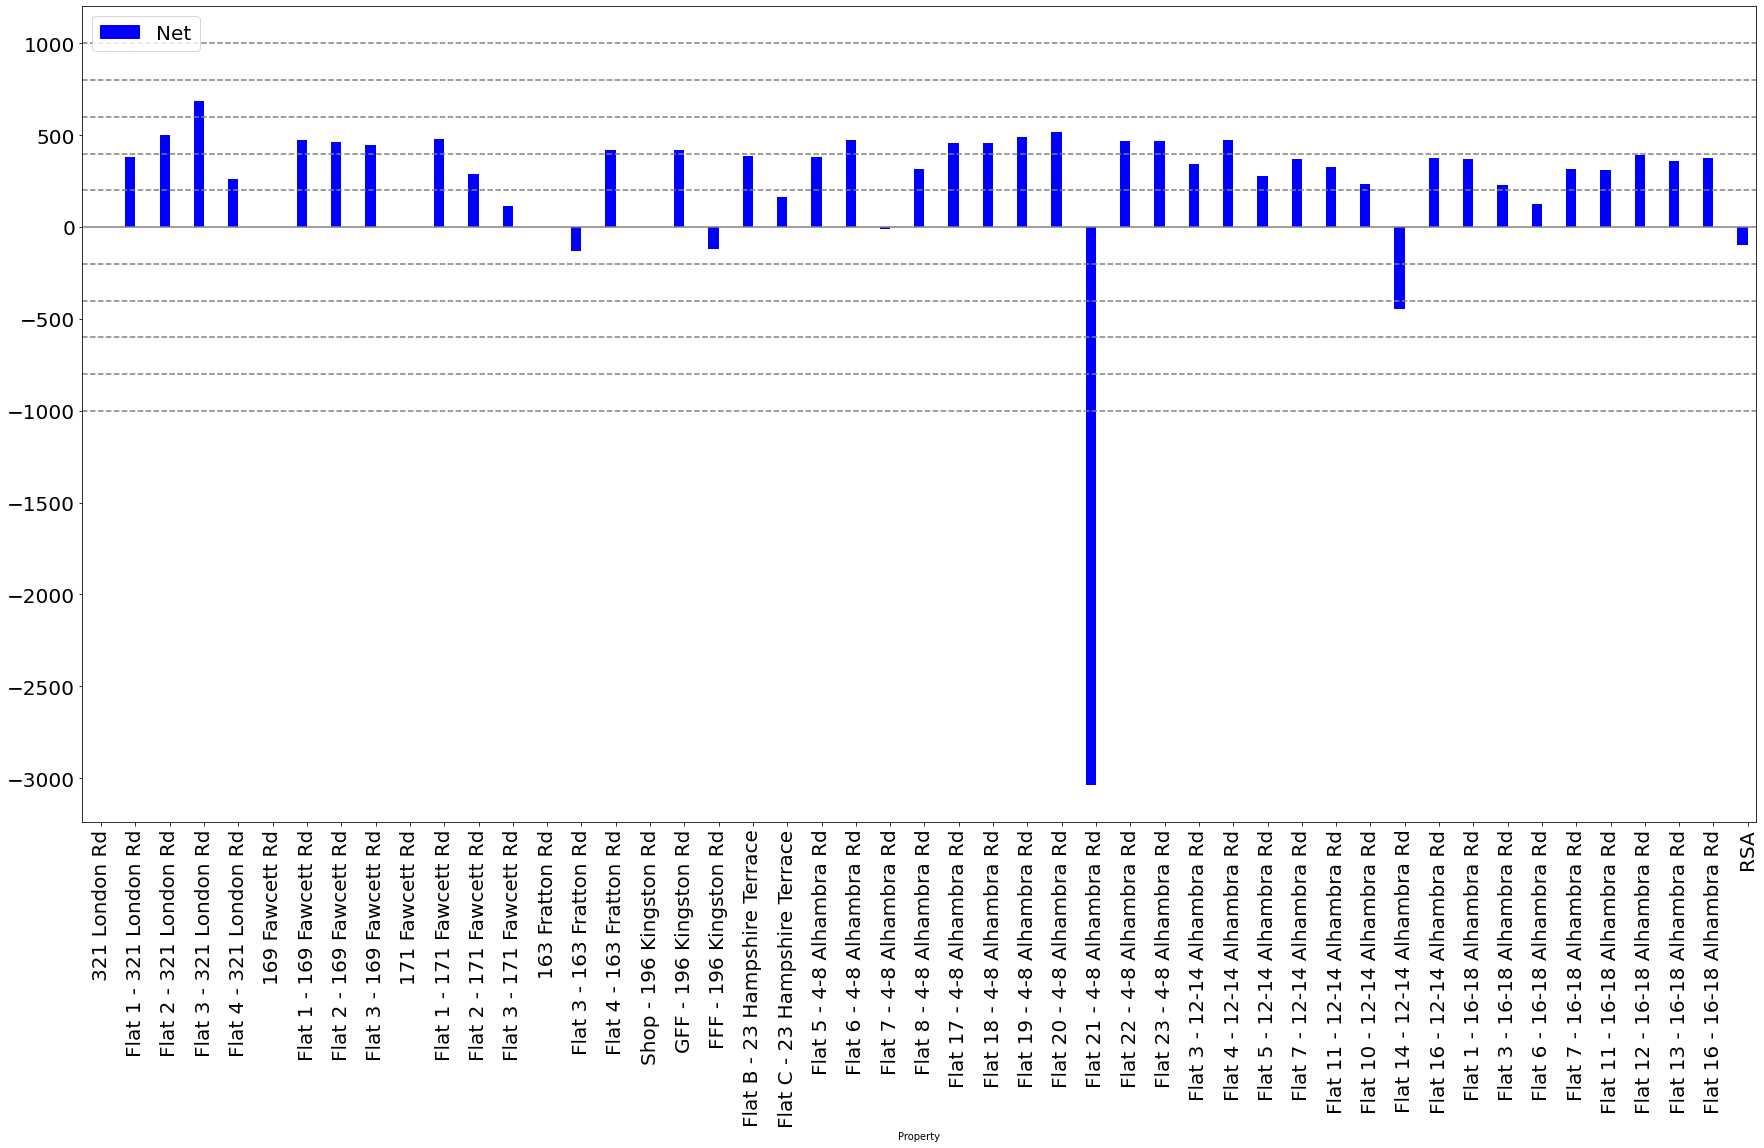

In [5]:
plot_net_income(dfRs[:-1])

### Personal Expenses


Total PersonalExpense: £3,801.61


<AxesSubplot:title={'center':'PersonalExpense by Subcat (total £3,802)'}>

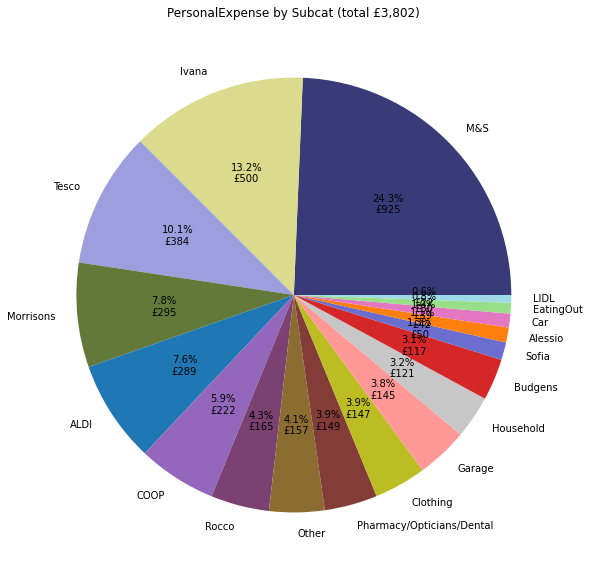

In [6]:
plot_personal_expense_by_subcat(dfAll, start, end)


### Accounts Check
Check Drawings against expenses

In [7]:
dfAll[(dfAll.Cat=='RegularPayment')|(dfAll.Cat=='PersonalExpense')|(dfAll.Cat=='Hilltop')|(dfAll.Cat=='HMRCDD')|(dfAll.Cat=='Drawings')|(dfAll.Cat=='SchoolFee')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
Hilltop,-300.00,0.0
PersonalExpense,-4015.99,0.0
RegularPayment,-1136.90,0.0
SchoolFee,-2884.62,0.0


In [8]:
dfAll.groupby(['Account','Cat']).sum().style.apply(custom_style_accounts_cat, axis=1)

#### Mortgage check
Check mortgages refunded from business account

In [9]:
dfMtg=dfAll[((dfAll.Cat=='Mortgage')|(dfAll.Cat=='MortgageRefund'))&(dfAll.Account!='60-83-71 00558156')].groupby(['Account','Cat']).Amount.sum()
dfMtg=dfMtg.reset_index().pivot('Account','Cat')
dfMtg.columns=dfMtg.columns.get_level_values(1)
if('MortgageRefund' not in dfMtg.columns):
    dfMtg['MortgageRefund']=0
dfMtg['Diff']=dfMtg.Mortgage + dfMtg.MortgageRefund
dfMtg

Cat,Mortgage,MortgageRefund,Diff
Account,,,
20-53-97 30728691,-20452.95,0,-20452.95


In [10]:
dfMtg['Diff'].sum()

-20452.95000000001

#### Rent check
Rents going to wrong account

In [11]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [12]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')].groupby(['Cat']).sum()

,Amount,Description
Cat,,


#### Property expense check
Property expenses and service charges taken from 3072 or 6045

In [13]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-06-26,20-74-09 60458872,-75.86,Card Purchase,AMAZON* 7C26Y8J25 ON 25 JUN BCC,RSA,NaN,PropertyExpense,Amazon


In [14]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
PropertyExpense,-75.86,0.0


In [15]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [16]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
